# Air Quality Insight
## Round 2: EDA and Feature Engineering

## 1. Load the Datasets

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

air = pd.read_csv("air_quality.csv")
stations = pd.read_csv("stations.csv")
weather = pd.read_csv("weather.csv")
traffic = pd.read_csv("traffic.csv")
calendar = pd.read_csv("calendar.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [33]:
print("Air Quality Dataset")
print(air.head())
print("\nShape:", air.shape)
print("\nData Types:")
print(air.dtypes)
print("\nMissing Values:")
print(air.isnull().sum())
print("\nDuplicate Rows:", air.duplicated().sum())

Air Quality Dataset
             timestamp          station  PM2.5   PM10    NO2   AQI
0  2026-01-10 00:00:00  Central_Traffic  59.16  86.70  29.10  63.0
1  2026-01-10 01:00:00  Central_Traffic  49.02  58.60  31.32  49.0
2  2026-01-10 02:00:00  Central_Traffic  49.98  80.46  27.61  59.0
3  2026-01-10 03:00:00  Central_Traffic  58.74  85.53  28.39  64.0
4  2026-01-10 04:00:00  Central_Traffic  55.87  96.20  35.37  63.0

Shape: (4038, 6)

Data Types:
timestamp        str
station          str
PM2.5        float64
PM10         float64
NO2          float64
AQI          float64
dtype: object

Missing Values:
timestamp     0
station       0
PM2.5        12
PM10         10
NO2           9
AQI           6
dtype: int64

Duplicate Rows: 6


In [34]:
print("Summary statistics:")
print(air.describe())

Summary statistics:
             PM2.5         PM10          NO2          AQI
count  4026.000000  4028.000000  4029.000000  4032.000000
mean     43.821458    72.401286    30.089253    52.478175
std      18.708311    28.438839    15.967056    22.735883
min       3.460000     4.660000     2.000000     8.000000
25%      33.870000    55.295000    20.670000    40.000000
50%      42.870000    71.175000    29.050000    51.000000
75%      52.567500    87.802500    36.460000    63.000000
max     850.000000  1100.000000   700.000000   999.000000


## 2. Data Cleaning

In [35]:
# Convert timestamp columns to date and time
air["timestamp"] = pd.to_datetime(air["timestamp"])
weather["timestamp"] = pd.to_datetime(weather["timestamp"])
traffic["timestamp"] = pd.to_datetime(traffic["timestamp"])
calendar["timestamp"] = pd.to_datetime(calendar["timestamp"])

# Correct station names
air["station"] = air["station"].str.strip().str.lower()
stations["station"] = stations["station"].str.strip().str.lower()
traffic["station"] = traffic["station"].str.strip().str.lower()

air["station"] = air["station"].replace({
    "central traffic": "central_traffic",
    "industrial east": "industrial_east",
    "market square": "market_square"
})

# Remove duplicate observations
air = air.drop_duplicates(subset=["timestamp", "station"])

print("Data cleaning completed!")

Data cleaning completed!


In [36]:
# Fill missing pollution values with their averages
pollution_columns = ["PM2.5", "PM10", "NO2", "AQI"]

for col in pollution_columns:
    air[col] = air[col].fillna(air[col].mean())

# Fill missing weather values with their averages
weather_columns = ["wind", "temperature", "humidity", "rain"]

for col in weather_columns:
    weather[col] = weather[col].fillna(weather[col].mean())

print("Missing values handled!")
print(air.isnull().sum())

Missing values handled!
timestamp    0
station      0
PM2.5        0
PM10         0
NO2          0
AQI          0
dtype: int64


## 3. Combining the Datasets

In [37]:
# Combine air quality with station information
data = pd.merge(air, stations, on="station", how="left")

# Add weather information
data = pd.merge(data, weather, on="timestamp", how="left")

# Add traffic information
data = pd.merge(
    data, traffic,
    on=["timestamp", "station"],
    how="left"
)

# Add calendar information
data = pd.merge(data, calendar, on="timestamp", how="left")

print("Datasets merged successfully!")
print("Final shape:", data.shape)
print(data.head())

Datasets merged successfully!
Final shape: (4032, 17)
            timestamp          station  PM2.5   PM10    NO2   AQI  \
0 2026-01-10 00:00:00  central_traffic  59.16  86.70  29.10  63.0   
1 2026-01-10 01:00:00  central_traffic  49.02  58.60  31.32  49.0   
2 2026-01-10 02:00:00  central_traffic  49.98  80.46  27.61  59.0   
3 2026-01-10 03:00:00  central_traffic  58.74  85.53  28.39  64.0   
4 2026-01-10 04:00:00  central_traffic  55.87  96.20  35.37  63.0   

      location land_use_type  wind  temperature  humidity  rain  \
0  City Centre       traffic  1.80         18.5      52.8   0.0   
1  City Centre       traffic  2.86         16.4      51.6   0.0   
2  City Centre       traffic  3.20         17.0      59.0   0.0   
3  City Centre       traffic  1.15         14.1      48.6   0.0   
4  City Centre       traffic  1.17         17.4      48.1   0.0   

   traffic_volume  peak_flag   weekday  holiday  season  
0             432          0  Saturday        0  Winter  
1           

## 4. Exploratory Data Analysis (EDA)

### 4.1 Average AQI at Different Stations

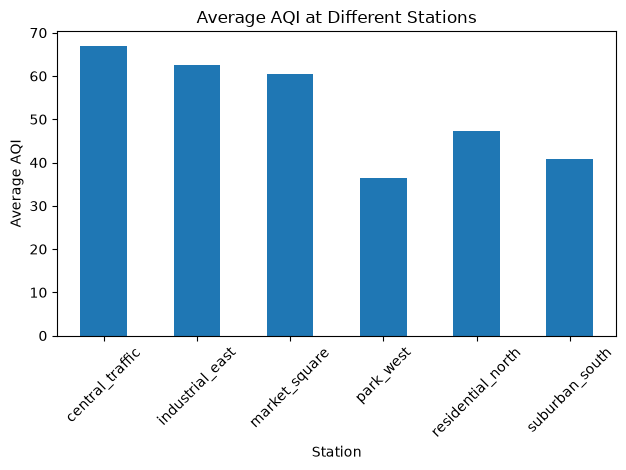

In [38]:
station_aqi = data.groupby("station")["AQI"].mean()
station_aqi.plot(kind="bar")
plt.title("Average AQI at Different Stations")
plt.xlabel("Station")
plt.ylabel("Average AQI")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 4.2 Pollution by Hour

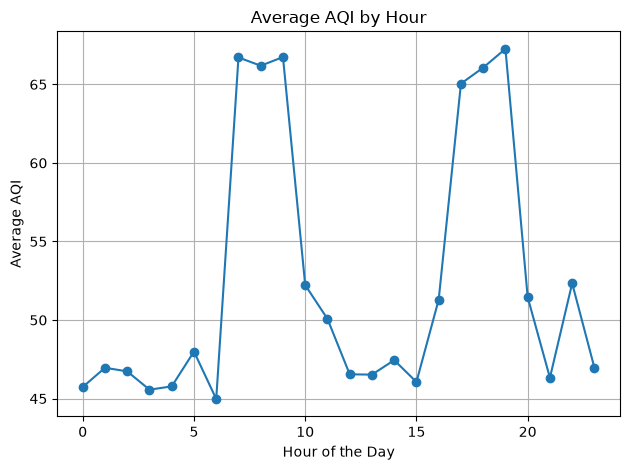

In [39]:
data["hour"] = data["timestamp"].dt.hour
hour_aqi = data.groupby("hour")["AQI"].mean()
hour_aqi.plot(kind="line", marker="o")
plt.title("Average AQI by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Average AQI")
plt.grid()
plt.tight_layout()
plt.show()

### 4.3 Wind Speed and PM2.5

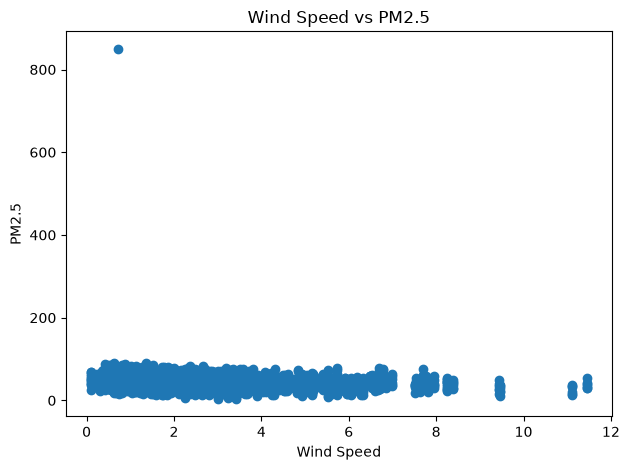

In [40]:
plt.scatter(data["wind"], data["PM2.5"])
plt.title("Wind Speed vs PM2.5")
plt.xlabel("Wind Speed")
plt.ylabel("PM2.5")
plt.tight_layout()
plt.show()

### 4.4 Traffic Volume and AQI

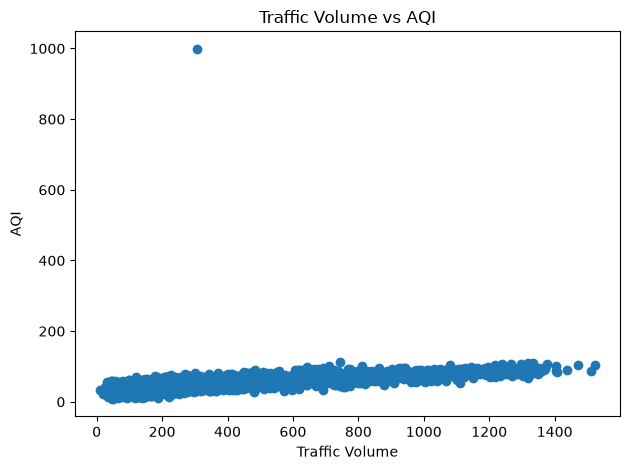

In [41]:
plt.scatter(data["traffic_volume"], data["AQI"])
plt.title("Traffic Volume vs AQI")
plt.xlabel("Traffic Volume")
plt.ylabel("AQI")
plt.tight_layout()
plt.show()

### 4.5 Rainfall and AQI

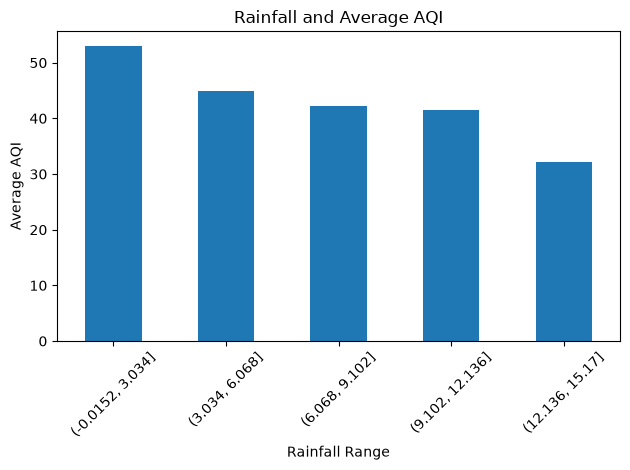

In [42]:
rain_aqi = data.groupby(
    pd.cut(data["rain"], bins=5, duplicates="drop"),
    observed=False
)["AQI"].mean()
rain_aqi.plot(kind="bar")
plt.title("Rainfall and Average AQI")
plt.xlabel("Rainfall Range")
plt.ylabel("Average AQI")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 4.6 Seasonal Pollution Pattern

The supplied synthetic data covers January and February only, so it mainly represents winter. A meaningful comparison across all seasons requires a dataset that includes multiple seasons.

## 5. Correlation Analysis

                   PM2.5      PM10       NO2       AQI      wind      rain  \
PM2.5           1.000000  0.576677  0.425275  0.528779 -0.164476 -0.136568   
PM10            0.576677  1.000000  0.471882  0.600538 -0.142205 -0.137548   
NO2             0.425275  0.471882  1.000000  0.471963 -0.118738  0.012825   
AQI             0.528779  0.600538  0.471963  1.000000 -0.162155 -0.113089   
wind           -0.164476 -0.142205 -0.118738 -0.162155  1.000000  0.028812   
rain           -0.136568 -0.137548  0.012825 -0.113089  0.028812  1.000000   
traffic_volume  0.541604  0.600311  0.663621  0.586387 -0.018207  0.036434   

                traffic_volume  
PM2.5                 0.541604  
PM10                  0.600311  
NO2                   0.663621  
AQI                   0.586387  
wind                 -0.018207  
rain                  0.036434  
traffic_volume        1.000000  


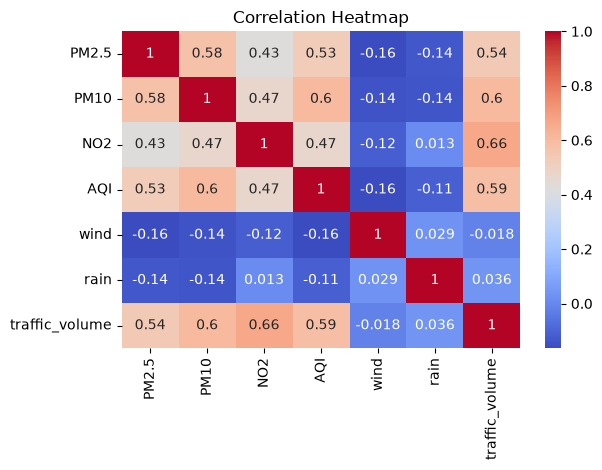

In [43]:
columns = ["PM2.5", "PM10", "NO2", "AQI", "wind", "rain", "traffic_volume"]
correlation = data[columns].corr()

print(correlation)

sns.heatmap(correlation, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## 6. Feature Engineering

In [44]:
# Create simple time-based features
data["day"] = data["timestamp"].dt.day
data["month"] = data["timestamp"].dt.month
data["weekend"] = (data["timestamp"].dt.dayofweek >= 5).astype(int)
data["rush_hour"] = data["hour"].isin([7, 8, 9, 17, 18, 19]).astype(int)

# Convert land-use categories into numeric columns
data = pd.get_dummies(data, columns=["land_use_type"], dtype=int)

print("New features created!")
print(data[["hour", "day", "month", "weekend", "rush_hour"]].head())

New features created!
   hour  day  month  weekend  rush_hour
0     0   10      1        1          0
1     1   10      1        1          0
2     2   10      1        1          0
3     3   10      1        1          0
4     4   10      1        1          0


## 7. Basic Feature Selection

In [45]:
# Find which numeric features are related to AQI
numeric_data = data.select_dtypes(include="number")
correlation = numeric_data.corr()["AQI"].abs().sort_values(ascending=False)

print("Features ranked by correlation with AQI:")
print(correlation)

selected_features = correlation[correlation > 0.1].index.tolist()
print("\nSelected features:")
print(selected_features)

Features ranked by correlation with AQI:
AQI                          1.000000
PM10                         0.600538
traffic_volume               0.586387
PM2.5                        0.528779
NO2                          0.471963
rush_hour                    0.352554
land_use_type_green_space    0.313639
peak_flag                    0.303884
land_use_type_traffic        0.285676
land_use_type_residential    0.261549
land_use_type_industrial     0.199148
wind                         0.162155
land_use_type_commercial     0.159651
humidity                     0.159137
month                        0.149364
rain                         0.113089
hour                         0.081419
temperature                  0.072676
weekend                      0.057502
day                          0.044258
holiday                           NaN
Name: AQI, dtype: float64

Selected features:
['AQI', 'PM10', 'traffic_volume', 'PM2.5', 'NO2', 'rush_hour', 'land_use_type_green_space', 'peak_flag', 'land_use_

## 8. Save the Final Dataset

In [46]:
data.to_csv("final_air_quality.csv", index=False)
print("Final dataset saved as final_air_quality.csv")
print("Final shape:", data.shape)

Final dataset saved as final_air_quality.csv
Final shape: (4032, 26)
